# 03. Gaussian Mixture Model (GMM) Experiments
**Project 26:** Card Fraud Triage  
**Team ID:** T047 (Section A)
**Lead:** Aditya Raj  

---
### What we are doing in this notebook:
1. Load our clean training data (only normal transactions) and validation data.
2. Scale features using `StandardScaler` (fit on train only!).
3. Train GMM with different numbers of clusters ($K = 1$ to $8$), each on 3 random seeds.
4. Check **AIC and BIC** (lower is better, tells us the best cluster count).
5. Compare **All 29 features** vs **Top 12 features**, and pick the best (feature set, K) by mean validation Average Precision.
7. Save the best GMM model for final evaluation.

### Changes from the first version
- **Feature list** is read from `configs/gmm_features.json`, which notebook 02 builds from the **training period only** (no validation/test labels).
- **EM is run with `n_init=5`** and repeated over **3 random seeds**, because a single EM run can land in very different solutions depending on initialisation.
- **K is searched from 1 to 8** for **both** feature sets.
- **Main metric is Average Precision (AP)** (`average_precision_score`). Trapezoidal PR-AUC is still shown for comparison, but it can overstate the area on step-shaped PR curves.
- **The champion is the (feature set, K) with the highest mean validation AP across seeds.** The min–max range across seeds is reported so unstable choices are visible. AIC and BIC are printed for reference.

### Step 1: Import libraries

In [1]:
import os
import json
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import precision_recall_curve, auc, average_precision_score

K_VALUES = [1, 2, 3, 4, 5, 6, 7, 8]
SEEDS = [0, 1, 2]
GMM_PARAMS = dict(covariance_type='full', reg_covar=1e-5, max_iter=200, n_init=5)

print("Libraries imported!")

Libraries imported!


### Step 2: Load clean train and validation data

In [2]:
train_path = '../data/processed/train_legit.csv'
val_path = '../data/processed/val_mixed.csv'

if not os.path.exists(train_path):
    train_path = 'data/processed/train_legit.csv'
    val_path = 'data/processed/val_mixed.csv'

train_df = pd.read_csv(train_path)
val_df = pd.read_csv(val_path)

print("Train shape (normal only):", train_df.shape)
print("Validation shape (mixed): ", val_df.shape)
print("Number of frauds in validation:", (val_df['Class'] == 1).sum())

Train shape (normal only): (169893, 31)
Validation shape (mixed):  (56745, 31)
Number of frauds in validation: 57


### Step 3: Helper to prepare features and score a GMM
Amount is log-transformed and the `StandardScaler` is fit on the training data only.
Anomaly score = negative log-likelihood (higher = more abnormal).

In [3]:
def prepare(features):
    X_tr = train_df[features].copy()
    X_va = val_df[features].copy()
    if 'Amount' in features:
        X_tr['Amount'] = np.log1p(X_tr['Amount'])
        X_va['Amount'] = np.log1p(X_va['Amount'])
    scaler = StandardScaler().fit(X_tr)
    return scaler.transform(X_tr), scaler.transform(X_va), scaler

def fit_one(X_tr, X_va, k, seed):
    gmm = GaussianMixture(n_components=k, random_state=seed, **GMM_PARAMS).fit(X_tr)
    scores = -gmm.score_samples(X_va)
    prec, rec, _ = precision_recall_curve(y_val, scores)
    return {'K': k, 'seed': seed,
            'AP': average_precision_score(y_val, scores),
            'PR_AUC_trapz': auc(rec, prec),
            'train_loglik': gmm.score(X_tr),
            'AIC': gmm.aic(X_tr), 'BIC': gmm.bic(X_tr), 'model': gmm}

def run_grid(X_tr, X_va, seeds):
    # All (K, seed) fits run in parallel on all CPU cores
    rows = Parallel(n_jobs=-1)(delayed(fit_one)(X_tr, X_va, k, s) for k in K_VALUES for s in seeds)
    df = pd.DataFrame(rows)
    for k, g in df.groupby('K'):
        print(f"K={k}: AP per seed = {[round(a, 3) for a in g['AP']]}")
    return df

y_val = val_df['Class'].values
print(f"Random-guess AP on validation = fraud rate = {y_val.mean():.4f}")

Random-guess AP on validation = fraud rate = 0.0010


### Step 4: Experiment 1 - All 29 features

In [4]:
all_features = [f'V{i}' for i in range(1, 29)] + ['Amount']
X_tr_all, X_va_all, _ = prepare(all_features)

print("GMM on all 29 features:")
df_all = run_grid(X_tr_all, X_va_all, seeds=SEEDS)

GMM on all 29 features:


K=1: AP per seed = [0.074, 0.074, 0.074]
K=2: AP per seed = [0.079, 0.079, 0.371]
K=3: AP per seed = [0.638, 0.343, 0.666]
K=4: AP per seed = [0.066, 0.065, 0.074]
K=5: AP per seed = [0.058, 0.647, 0.194]
K=6: AP per seed = [0.067, 0.078, 0.059]
K=7: AP per seed = [0.232, 0.227, 0.128]
K=8: AP per seed = [0.305, 0.419, 0.246]


### Step 5: Experiment 2 - Selected 12 features (from notebook 02)

In [5]:
config_path = '../configs/gmm_features.json'
if not os.path.exists(config_path):
    config_path = 'configs/gmm_features.json'
with open(config_path) as f:
    top_features = json.load(f)['selected_features']
print("Selected features:", top_features)

X_tr_top, X_va_top, scaler_top = prepare(top_features)

print("\nGMM on selected 12 features:")
df_top = run_grid(X_tr_top, X_va_top, seeds=SEEDS)

Selected features: ['V14', 'V10', 'V12', 'V11', 'V17', 'V4', 'V3', 'V16', 'V7', 'V2', 'V9', 'Amount']



GMM on selected 12 features:


K=1: AP per seed = [0.266, 0.266, 0.266]
K=2: AP per seed = [0.213, 0.201, 0.201]
K=3: AP per seed = [0.205, 0.199, 0.199]
K=4: AP per seed = [0.197, 0.198, 0.197]
K=5: AP per seed = [0.212, 0.198, 0.198]
K=6: AP per seed = [0.081, 0.628, 0.295]
K=7: AP per seed = [0.065, 0.069, 0.068]
K=8: AP per seed = [0.095, 0.065, 0.066]


### Step 6: Summary table and choice of champion
For each (feature set, K): mean, min and max validation AP over the seeds, plus AIC/BIC (mean over seeds).
The champion is the row with the highest **mean validation AP**.

In [6]:
def summarise(df, name):
    s = df.groupby('K').agg(AP_mean=('AP', 'mean'), AP_min=('AP', 'min'), AP_max=('AP', 'max'),
                            PR_AUC_trapz_mean=('PR_AUC_trapz', 'mean'),
                            AIC=('AIC', 'mean'), BIC=('BIC', 'mean')).reset_index()
    s.insert(0, 'features', name)
    return s

summary = pd.concat([summarise(df_all, 'all_29'), summarise(df_top, 'selected_12')], ignore_index=True)
pd.set_option('display.float_format', lambda v: f'{v:,.3f}' if abs(v) < 100 else f'{v:,.0f}')
print(summary.to_string(index=False))

best = summary.loc[summary['AP_mean'].idxmax()]
best_set, best_k = best['features'], int(best['K'])
print(f"\nChampion by mean validation AP: features = {best_set}, K = {best_k} "
      f"(AP mean {best['AP_mean']:.3f}, range {best['AP_min']:.3f}-{best['AP_max']:.3f})")
for name in ['all_29', 'selected_12']:
    s = summary[summary['features'] == name]
    print(f"K preferred by BIC for {name}: {int(s.loc[s['BIC'].idxmin(), 'K'])}")

   features  K  AP_mean  AP_min  AP_max  PR_AUC_trapz_mean        AIC        BIC
     all_29  1    0.074   0.074   0.074              0.071 13,696,720 13,701,380
     all_29  2    0.176   0.079   0.371              0.174  6,626,146  6,635,476
     all_29  3    0.549   0.343   0.666              0.548  3,398,903  3,412,903
     all_29  4    0.068   0.065   0.074              0.066 -1,236,710 -1,218,040
     all_29  5    0.300   0.058   0.647              0.298 -2,689,361 -2,666,021
     all_29  6    0.068   0.059   0.078              0.066 -3,204,076 -3,176,066
     all_29  7    0.196   0.128   0.232              0.192 -4,019,895 -3,987,216
     all_29  8    0.323   0.246   0.419              0.321 -5,160,316 -5,122,966
selected_12  1    0.266   0.266   0.266              0.256  5,642,562  5,643,466
selected_12  2    0.205   0.201   0.213              0.199  4,668,928  4,670,746
selected_12  3    0.201   0.199   0.205              0.194  4,384,729  4,387,461
selected_12  4    0.197   0.

### Step 7: Plotting the comparison

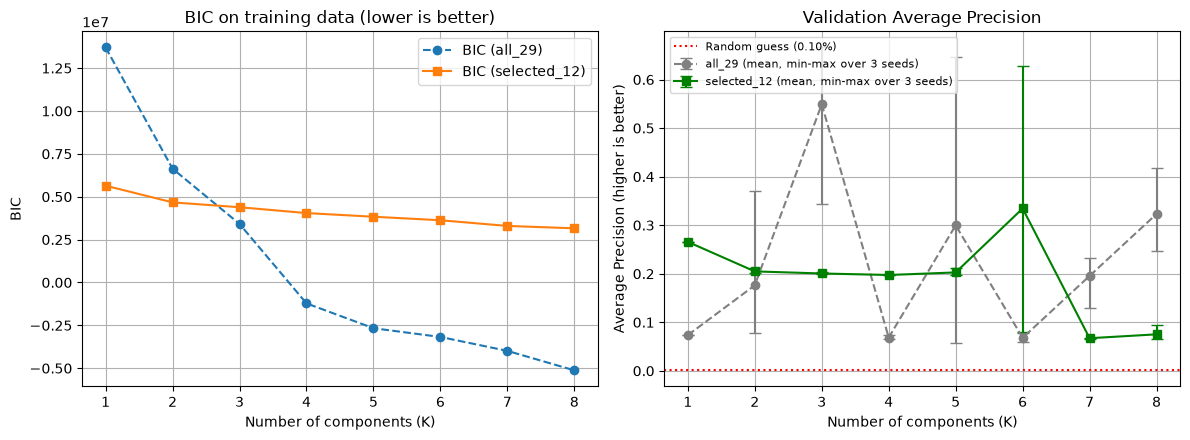

In [7]:
fig_dir = '../results/figures'
if not os.path.exists(fig_dir):
    fig_dir = 'results/figures'

plt.figure(figsize=(12, 4.5))

plt.subplot(1, 2, 1)
for name, style in [('all_29', 'o--'), ('selected_12', 's-')]:
    s = summary[summary['features'] == name]
    plt.plot(s['K'], s['BIC'], style, label=f'BIC ({name})')
plt.title("BIC on training data (lower is better)")
plt.xlabel("Number of components (K)")
plt.ylabel("BIC")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
for name, color, style in [('all_29', 'grey', 'o--'), ('selected_12', 'green', 's-')]:
    s = summary[summary['features'] == name]
    plt.errorbar(s['K'], s['AP_mean'], yerr=[s['AP_mean'] - s['AP_min'], s['AP_max'] - s['AP_mean']],
                 fmt=style, color=color, capsize=4, label=f'{name} (mean, min-max over {len(SEEDS)} seeds)')
plt.axhline(y=y_val.mean(), color='red', linestyle=':', label=f'Random guess ({y_val.mean()*100:.2f}%)')
plt.title("Validation Average Precision")
plt.xlabel("Number of components (K)")
plt.ylabel("Average Precision (higher is better)")
plt.legend(fontsize=8)
plt.grid(True)

plt.tight_layout()
plt.savefig(os.path.join(fig_dir, 'fig5_gmm_component_selection.png'))
plt.show()

### Step 8: Save the champion model

In [8]:
# Among the seeds of the champion configuration, keep the fit with the best validation AP.
# The seed is treated like any other hyperparameter: chosen on validation, test still untouched.
# (Highest training log-likelihood is NOT used: it favours fits with collapsed, near-singular
# components, which have huge likelihood but rank fraud poorly.)
grid = df_all if best_set == 'all_29' else df_top
chosen = grid[grid['K'] == best_k].sort_values('AP', ascending=False).iloc[0]
best_gmm = chosen['model']
best_features = all_features if best_set == 'all_29' else top_features
_, _, best_scaler = prepare(best_features)
print(f"Champion: features = {best_set}, K = {best_k}, seed = {chosen['seed']}, validation AP = {chosen['AP']:.4f}")

models_dir = '../results/models'
if not os.path.exists(models_dir):
    models_dir = 'results/models'
os.makedirs(models_dir, exist_ok=True)

joblib.dump(best_gmm, os.path.join(models_dir, 'gmm_champion.joblib'))
joblib.dump(best_scaler, os.path.join(models_dir, 'gmm_scaler.joblib'))
joblib.dump(best_features, os.path.join(models_dir, 'gmm_features.joblib'))

print("Champion GMM model, scaler and feature list saved!")

Champion: features = all_29, K = 3, seed = 2, validation AP = 0.6661
Champion GMM model, scaler and feature list saved!
